In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

print("Libraries imported successfully.")
print("SHAP version:", shap.__version__)

Libraries imported successfully.
SHAP version: 0.49.1


In [7]:

# Load the exact test data used by the XGBoost model

X_test = pd.read_csv("../models/ml/xgb_X_test.csv")
y_test = pd.read_csv("../models/ml/xgb_y_test.csv").squeeze()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Number of features:", X_test.shape[1])


X_test shape: (10000, 39)
y_test shape: (10000,)
Number of features: 39


In [8]:
from xgboost import XGBRegressor

# Load the trained XGBoost model
xgb_model = XGBRegressor()

xgb_model.load_model("../models/ml/xgb_model.json")

print("XGBoost model loaded successfully.")
print("Number of model features:", len(xgb_model.feature_names_in_))


XGBoost model loaded successfully.
Number of model features: 39


In [9]:
print("X_test features:", X_test.shape[1])
print("Model features:", len(xgb_model.feature_names_in_))

if X_test.shape[1] == len(xgb_model.feature_names_in_):
    print("Feature count matches successfully.")
else:
    print("ERROR: Feature count does not match.")


X_test features: 39
Model features: 39
Feature count matches successfully.


In [10]:

# Create a representative sample for SHAP analysis

X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

print("SHAP sample shape:", X_shap.shape)


SHAP sample shape: (1000, 39)


In [11]:
# Prediction function for SHAP

def predict_fn(data):
    return xgb_model.predict(data)

# Test the prediction function
test_predictions = predict_fn(X_shap)

print("Prediction function working successfully.")
print("Prediction shape:", test_predictions.shape)
print("First 5 predictions:", test_predictions[:5])

Prediction function working successfully.
Prediction shape: (1000,)
First 5 predictions: [639.5701  637.85034 585.7546  671.9051  670.5555 ]


In [12]:
explainer = shap.Explainer(
    predict_fn,
    X_shap
)

print("Model-agnostic SHAP explainer created successfully.")
print("Explainer type:", type(explainer).__name__)

Model-agnostic SHAP explainer created successfully.
Explainer type: PermutationExplainer


In [13]:
shap_values = explainer(
    X_shap
)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)
print("X_shap shape:", X_shap.shape)

PermutationExplainer explainer: 1001it [00:42, 20.19it/s]                         

SHAP values calculated successfully.
SHAP values shape: (1000, 39)
X_shap shape: (1000, 39)


C:\Users\rosha\AppData\Local\Temp\ipykernel_22480\1521436329.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


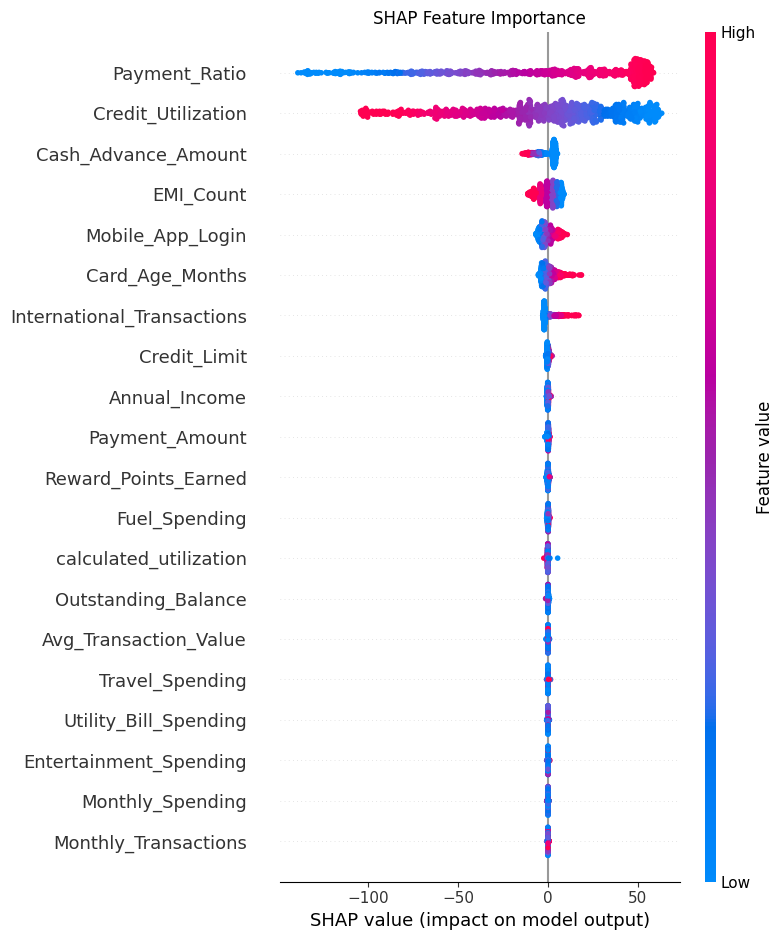

SHAP summary plot saved successfully.


In [14]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)

plt.title("SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    "../results/figures/shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP summary plot saved successfully.")

In [15]:
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("Top 15 SHAP features:")
display(shap_importance.head(15))

Top 15 SHAP features:


,Feature,Mean_Absolute_SHAP
0,Payment_Ratio,44.971282
1,Credit_Utilization,34.183624
2,Cash_Advance_Amount,4.409472
3,EMI_Count,4.377352
4,Mobile_App_Login,3.125711
5,Card_Age_Months,2.900163
6,International_Transactions,2.722978
7,Credit_Limit,0.407717
8,Annual_Income,0.239322
9,Payment_Amount,0.217198


In [16]:
# Analyze the direction of SHAP impact for the top features

top_features = shap_importance.head(10)["Feature"].tolist()

direction_analysis = []

for feature in top_features:
    feature_index = X_shap.columns.get_loc(feature)

    feature_values = X_shap[feature].values
    feature_shap = shap_values.values[:, feature_index]

    correlation = np.corrcoef(
        feature_values,
        feature_shap
    )[0, 1]

    direction_analysis.append({
        "Feature": feature,
        "SHAP_Value_Correlation": correlation
    })

direction_analysis = pd.DataFrame(direction_analysis)

display(direction_analysis)

,Feature,SHAP_Value_Correlation
0,Payment_Ratio,0.999741
1,Credit_Utilization,-0.999617
2,Cash_Advance_Amount,-0.617560
3,EMI_Count,-0.990828
4,Mobile_App_Login,0.987629
5,Card_Age_Months,0.991101
6,International_Transactions,0.991025
7,Credit_Limit,0.647494
8,Annual_Income,0.648812
9,Payment_Amount,0.421232


In [17]:
# Save SHAP feature importance results

shap_importance.to_csv(
    "../results/shap_feature_importance.csv",
    index=False
)

print("SHAP feature importance saved successfully.")
print("File: ../results/shap_feature_importance.csv")

SHAP feature importance saved successfully.
File: ../results/shap_feature_importance.csv


C:\Users\rosha\AppData\Local\Temp\ipykernel_22480\1261390520.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


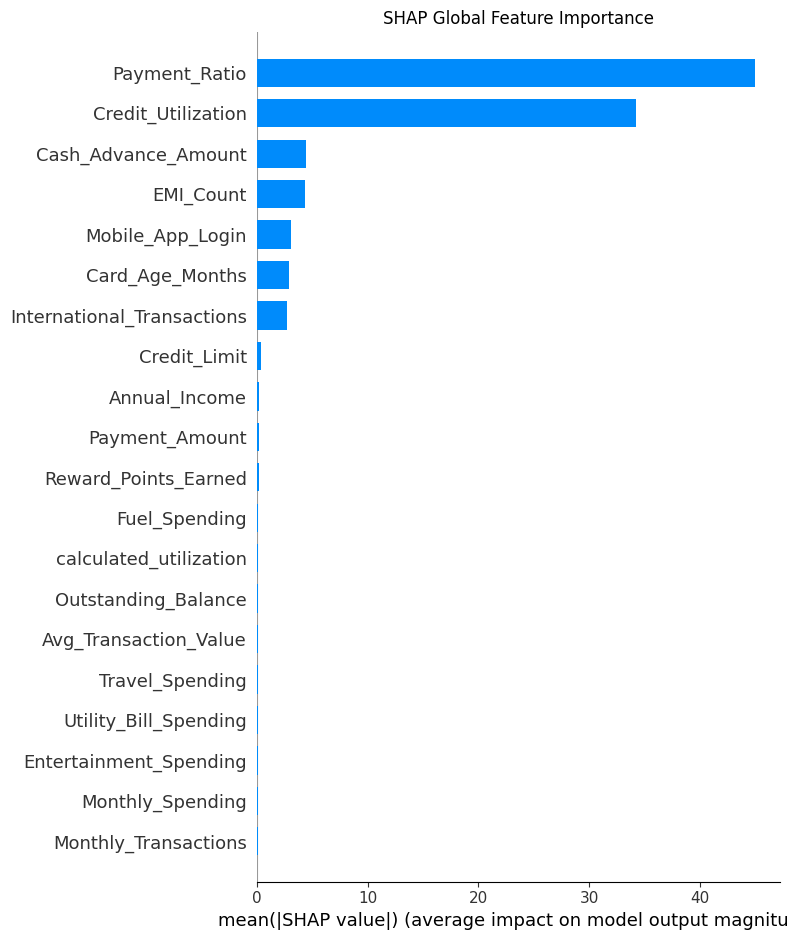

SHAP bar plot saved successfully.


In [18]:
plt.figure()

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()

plt.savefig(
    "../results/figures/shap_bar_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP bar plot saved successfully.")

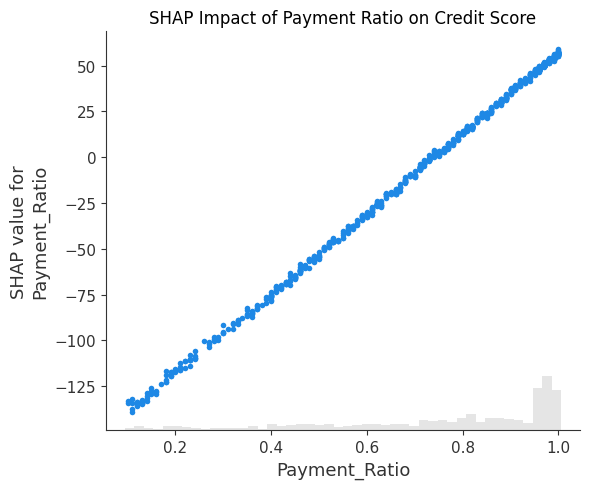

Payment Ratio SHAP plot saved successfully.


In [19]:
shap.plots.scatter(
    shap_values[:, "Payment_Ratio"],
    show=False
)

plt.title("SHAP Impact of Payment Ratio on Credit Score")
plt.tight_layout()

plt.savefig(
    "../results/figures/shap_payment_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Payment Ratio SHAP plot saved successfully.")

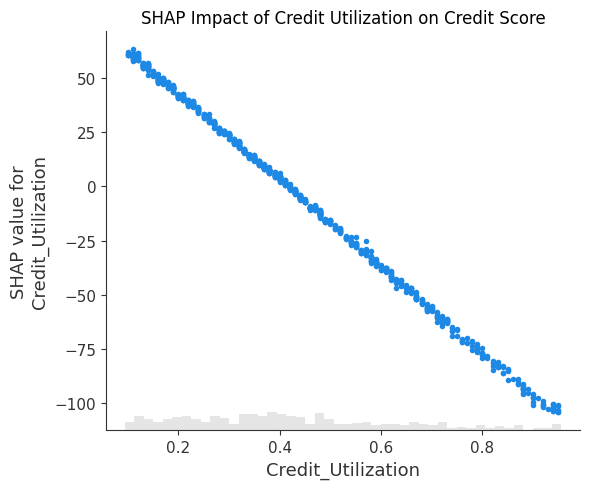

Credit Utilization SHAP plot saved successfully.


In [20]:
shap.plots.scatter(
    shap_values[:, "Credit_Utilization"],
    show=False
)

plt.title("SHAP Impact of Credit Utilization on Credit Score")
plt.tight_layout()

plt.savefig(
    "../results/figures/shap_credit_utilization.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Credit Utilization SHAP plot saved successfully.")

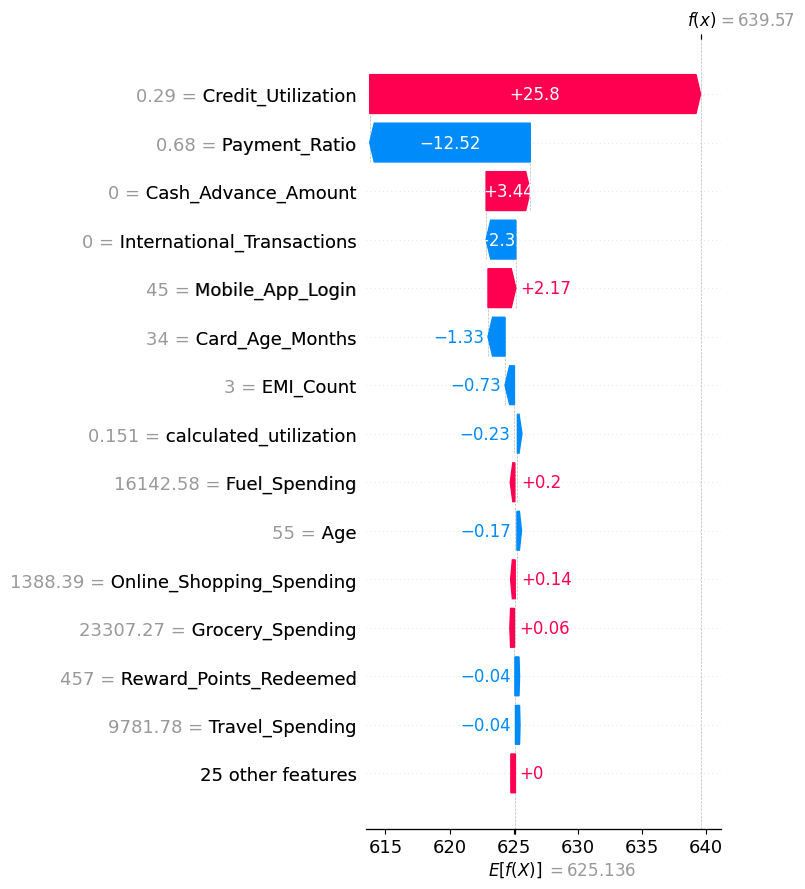

SHAP waterfall plot saved successfully.
Actual Credit Score: 580
Predicted Credit Score: 639.5701


In [21]:
# Explain one individual prediction

sample_index = 0

shap.plots.waterfall(
    shap_values[sample_index],
    max_display=15,
    show=False
)

plt.tight_layout()

plt.savefig(
    "../results/figures/shap_waterfall_sample_0.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP waterfall plot saved successfully.")
print("Actual Credit Score:", y_test.iloc[sample_index])
print("Predicted Credit Score:", xgb_model.predict(X_shap.iloc[[sample_index]])[0])

In [22]:
# Extract SHAP contributions for the selected customer

sample_explanation = shap_values[sample_index]

waterfall_data = pd.DataFrame({
    "Feature": X_shap.columns,
    "Feature_Value": X_shap.iloc[sample_index].values,
    "SHAP_Value": sample_explanation.values
})

waterfall_data["Absolute_SHAP"] = np.abs(
    waterfall_data["SHAP_Value"]
)

waterfall_data = waterfall_data.sort_values(
    by="Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("Top 15 feature contributions for this customer:")
display(waterfall_data.head(15))

Top 15 feature contributions for this customer:


,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
0,Credit_Utilization,0.290000,25.795711,25.795711
1,Payment_Ratio,0.680000,-12.521459,12.521459
2,Cash_Advance_Amount,0.000000,3.444671,3.444671
3,International_Transactions,0.000000,-2.319980,2.319980
4,Mobile_App_Login,45.000000,2.173092,2.173092
5,Card_Age_Months,34.000000,-1.328043,1.328043
6,EMI_Count,3.000000,-0.734658,0.734658
7,calculated_utilization,0.151298,-0.229856,0.229856
8,Fuel_Spending,16142.580000,0.202204,0.202204
9,Age,55.000000,-0.167541,0.167541


In [23]:
# Verify SHAP prediction reconstruction

base_value = shap_values[sample_index].base_values
shap_sum = shap_values[sample_index].values.sum()
reconstructed_prediction = base_value + shap_sum

model_prediction = xgb_model.predict(
    X_shap.iloc[[sample_index]]
)[0]

print("SHAP base value:", base_value)
print("Sum of SHAP values:", shap_sum)
print("Reconstructed prediction:", reconstructed_prediction)
print("Model prediction:", model_prediction)
print("Difference:", abs(reconstructed_prediction - model_prediction))

SHAP base value: 625.1363522338867
Sum of SHAP values: 14.433777160644583
Reconstructed prediction: 639.5701293945312
Model prediction: 639.5701
Difference: 0.0


In [24]:
# Save individual SHAP explanation

waterfall_data.to_csv(
    "../results/shap_sample_0_explanation.csv",
    index=False
)

print("Individual SHAP explanation saved successfully.")
print("File: ../results/shap_sample_0_explanation.csv")

Individual SHAP explanation saved successfully.
File: ../results/shap_sample_0_explanation.csv


In [25]:
# Create final SHAP summary table

final_shap_summary = shap_importance.head(10).copy()

final_shap_summary["Direction"] = (
    direction_analysis
    .set_index("Feature")
    .loc[final_shap_summary["Feature"], "SHAP_Value_Correlation"]
    .apply(
        lambda x: "Positive" if x > 0 else "Negative"
    )
    .values
)

print("Final SHAP summary:")
display(final_shap_summary)

Final SHAP summary:


,Feature,Mean_Absolute_SHAP,Direction
0,Payment_Ratio,44.971282,Positive
1,Credit_Utilization,34.183624,Negative
2,Cash_Advance_Amount,4.409472,Negative
3,EMI_Count,4.377352,Negative
4,Mobile_App_Login,3.125711,Positive
5,Card_Age_Months,2.900163,Positive
6,International_Transactions,2.722978,Positive
7,Credit_Limit,0.407717,Positive
8,Annual_Income,0.239322,Positive
9,Payment_Amount,0.217198,Positive


In [26]:
final_shap_summary.to_csv(
    "../results/shap_final_summary.csv",
    index=False
)

print("Final SHAP summary saved successfully.")
print("File: ../results/shap_final_summary.csv")

Final SHAP summary saved successfully.
File: ../results/shap_final_summary.csv
